# Supervised fine-tuning on arithmetic

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shoaibphysics/arithmetic-post-training/blob/main/notebooks/01_sft.ipynb)

Can a small language model learn to answer arithmetic questions reliably?

We fine-tune Qwen2.5-0.5B on two-digit addition and subtraction using
LoRA, then compare the base and fine-tuned models on held-out questions.

This notebook covers supervised learning. The next notebook explores
learning from correctness rewards.

### Setup

Locally, use the project's Python environment. In Colab, select a GPU
runtime. Colab outputs are saved to Google Drive.

The Colab installation requires this project to be available on GitHub.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    %pip install -q transformers==5.18.0 trl==1.16.0 peft==0.21.2 datasets==5.1.0 accelerate==1.15.0 pandas==3.0.6 matplotlib==3.11.2
    %pip install -q --no-deps git+https://github.com/shoaibphysics/arithmetic-post-training.git@main

In [2]:
from pathlib import Path

import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from arithmetic_post_training.arithmetic import make_arithmetic_data
from arithmetic_post_training.evaluation import evaluate_arithmetic

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    project_root = Path("/content/drive/MyDrive/arithmetic-post-training")
else:
    project_root = Path.cwd()
    if project_root.name == "notebooks":
        project_root = project_root.parent

run_dir = project_root / "runs" / "sft"
asset_dir = project_root / "assets" / "sft"
run_dir.mkdir(parents=True, exist_ok=True)
asset_dir.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Run outputs:", run_dir)
print("README assets:", asset_dir)

/Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps
Run outputs: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/sft
README assets: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/assets/sft


### Arithmetic data

We create addition and subtraction questions using operands from 10 to 99,
shuffle them with a fixed seed, and select 5,000 training, 500 validation,
and 1,000 test examples.

Each exact question appears in only one split. Operand order is preserved:
`24 + 37` and `37 + 24` are distinct inputs and may appear in different splits.

Addition and subtraction are approximately balanced after splitting.
Subtraction can produce negative answers. Multiplication is not included.

Each target response contains a single integer.

In [3]:
data = make_arithmetic_data(n_train=5000, n_val=500, n_test=1000, seed=42)

for split, examples in data.items():
    pd.DataFrame(examples).to_csv(run_dir / f"{split}.csv", index=False)

pd.DataFrame(data["train"]).head()

,prompt,completion
0,Question: What is 36 - 24?\nAnswer:,12
1,Question: What is 29 - 38?\nAnswer:,-9
2,Question: What is 30 + 90?\nAnswer:,120
3,Question: What is 94 - 20?\nAnswer:,74
4,Question: What is 94 - 32?\nAnswer:,62


### Base model

We use the pretrained Qwen2.5-0.5B base model.

Before training, we inspect its responses on 100 validation questions.
Evaluation uses greedy decoding with a maximum of eight new tokens.

A response is correct only if it contains a single integer whose value
matches the target, allowing surrounding whitespace. We also report
the valid-integer format rate separately.

In [4]:
model_name = "Qwen/Qwen2.5-0.5B"

tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float32).to(device)

base_validation = evaluate_arithmetic(model, tokenizer, data["validation"][:100])

print(f"Baseline validation accuracy: {base_validation['correct'].mean():.1%}")
print(f"Valid integer responses: {base_validation['valid'].mean():.1%}")
base_validation.head()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 649.11it/s]


Baseline validation accuracy: 0.0%
Valid integer responses: 0.0%


,prompt,response,expected,correct,valid
0,Question: What is 57 - 20?\nAnswer:,57 - 20 =,37,False,False
1,Question: What is 39 + 22?\nAnswer:,39 + 22 =,61,False,False
2,Question: What is 62 + 71?\nAnswer:,62 + 71 =,133,False,False
3,Question: What is 64 - 70?\nAnswer:,64 - 70 =,-6,False,False
4,Question: What is 42 - 32?\nAnswer:,42 - 32 =,10,False,False


### Supervised fine-tuning

During training, the model receives the question and correct answer.
It learns to predict each answer token from the preceding tokens.

The loss is the average negative log-probability of the target tokens:

$$
\mathcal{L}_{\mathrm{SFT}}
= -\frac{1}{|A|}\sum_{t \in A}
\log p_\theta(y_t \mid x, y_{<t}),
$$

where \(A\) includes the answer tokens and the end-of-sequence token.
Question and padding tokens are excluded from the loss.

LoRA trains small additional matrices while keeping the original model
weights frozen. We train for one epoch with an effective batch size of
16 on a single device.

In [5]:
lora = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM")

use_bf16 = device == "cuda" and torch.cuda.is_bf16_supported()

args = SFTConfig(
    output_dir=str(run_dir / "training"),
    num_train_epochs=1,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=16,
    learning_rate=2e-4,
    warmup_steps=10,
    optim="adamw_torch",
    max_length=64,
    completion_only_loss=True,
    loss_type="nll",
    packing=False,
    gradient_checkpointing=False,
    bf16=use_bf16,
    fp16=device == "cuda" and not use_bf16,
    dataloader_pin_memory=device == "cuda",
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=42)

trainer = SFTTrainer(
    model=model,
    args=args,
    train_dataset=Dataset.from_list(data["train"]),
    eval_dataset=Dataset.from_list(data["validation"]),
    processing_class=tokenizer,
    peft_config=lora)

trainer.model.print_trainable_parameters()

Truncating train dataset: 100%|██████████| 5000/5000 [00:00<00:00, 72118.63 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 5000/5000 [00:00<00:00, 565483.47 examples/s]
Dropping fully masked examples from eval dataset: 100%|██████████| 500/500 [00:00<00:00, 294461.11 examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [6]:
# Show the answer and end-of-sequence tokens included in the loss.
batch = trainer.data_collator([trainer.train_dataset[0]])
labels = batch["labels"][0]

print("Tokens included in the loss:", tokenizer.decode(labels[labels != -100]))

Tokens included in the loss:  12<|endoftext|>


In [7]:
trainer.train()

adapter_dir = run_dir / "adapter"
trainer.save_model(str(adapter_dir))
tokenizer.save_pretrained(str(adapter_dir))

(run_dir / "training-args.json").write_text(args.to_json_string())

history = pd.DataFrame(trainer.state.log_history)
history.to_csv(run_dir / "training.csv", index=False)

print("Saved adapter:", adapter_dir)

Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,0.000074,0.000025,0.000231,1.000000,91034.000000


Saved adapter: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/sft/adapter


### Training loss

The training curve shows loss averaged over each logging interval.
Validation loss is measured once, at the end of the epoch.

These losses measure prediction of the supplied answer tokens. We next
evaluate whether the model can generate correct answers independently.

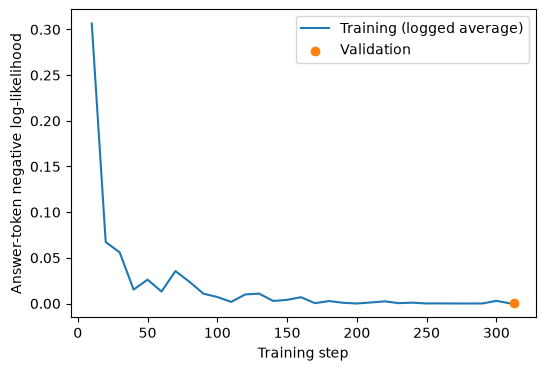

In [8]:
ax = history.dropna(subset=["loss"]).plot(
    x="step",
    y="loss",
    label="Training (logged average)",
    xlabel="Training step",
    ylabel="Answer-token negative log-likelihood",
    figsize=(6, 4))

validation = history.dropna(subset=["eval_loss"])
ax.scatter(
    validation["step"],
    validation["eval_loss"],
    label="Validation",
    color="tab:orange",
    zorder=3)
ax.legend()

ax.figure.savefig(asset_dir / "loss.png", dpi=160, bbox_inches="tight")

### Held-out evaluation

Both models answer the same 1,000 test questions with identical decoding
settings. These exact questions were excluded from fine-tuning.

Disabling the LoRA adapter recovers the original frozen base model,
allowing a direct comparison without loading another copy.

We report strict answer accuracy and valid-integer format rate.
The saved checkpoint contains the adapter; loading it later also
requires the original Qwen base model.

In [9]:
sft_test = evaluate_arithmetic(trainer.model, tokenizer, data["test"])

with trainer.model.disable_adapter():
    base_test = evaluate_arithmetic(trainer.model, tokenizer, data["test"])

base_test.to_csv(run_dir / "base-test.csv", index=False)
sft_test.to_csv(run_dir / "sft-test.csv", index=False)

results = pd.DataFrame([
    {
        "model": name,
        "n_test": len(frame),
        "n_correct": int(frame["correct"].sum()),
        "accuracy": frame["correct"].mean(),
        "valid_format": frame["valid"].mean(),
    }
    for name, frame in [("Base", base_test), ("SFT", sft_test)]
]).set_index("model")

results.to_csv(asset_dir / "results.csv")
results

,n_test,n_correct,accuracy,valid_format
model,,,,
Base,1000,1,0.001,0.001
SFT,1000,1000,1.000,1.000


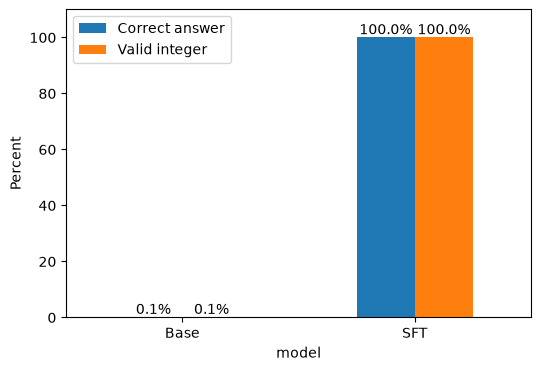

In [10]:
ax = results[["accuracy", "valid_format"]].mul(100).rename(
    columns={"accuracy": "Correct answer", "valid_format": "Valid integer"}
).plot.bar(
    rot=0,
    ylim=(0, 110),
    ylabel="Percent",
    figsize=(6, 4),
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

ax.figure.savefig(asset_dir / "accuracy.png", dpi=160, bbox_inches="tight")

### Example responses

We show the first ten test questions in their seeded order, without
selecting examples based on whether training improved the answer.

The following error table lists remaining incorrect SFT responses.
An empty table means every test response passed the evaluator.

In [11]:
examples = base_test.merge(
    sft_test,
    on=["prompt", "expected"],
    suffixes=("_base", "_sft"),
)[[
    "prompt",
    "expected",
    "response_base",
    "response_sft",
    "correct_base",
    "correct_sft",
]].head(10)

examples.to_csv(asset_dir / "examples.csv", index=False)
examples

,prompt,expected,response_base,response_sft,correct_base,correct_sft
0,Question: What is 10 + 49?\nAnswer:,59,10 + 49 =,59,False,True
1,Question: What is 50 + 24?\nAnswer:,74,50 + 24 =,74,False,True
2,Question: What is 31 - 71?\nAnswer:,-40,31 - 71 =,-40,False,True
3,Question: What is 37 - 73?\nAnswer:,-36,37 - 73 =,-36,False,True
4,Question: What is 10 + 18?\nAnswer:,28,10 + 18 =,28,False,True
5,Question: What is 87 + 44?\nAnswer:,131,87 + 44 =,131,False,True
6,Question: What is 16 - 17?\nAnswer:,-1,16 - 17 =,-1,False,True
7,Question: What is 44 + 30?\nAnswer:,74,44 + 30 =,74,False,True
8,Question: What is 24 + 95?\nAnswer:,119,24 + 95 =,119,False,True
9,Question: What is 78 + 31?\nAnswer:,109,78 + 31 =,109,False,True


In [12]:
errors = sft_test.loc[~sft_test["correct"]]

print(f"Incorrect answers: {len(errors)} / {len(sft_test)}")
errors.head(10)

Incorrect answers: 0 / 1000


,prompt,response,expected,correct,valid


### Interpretation

After one epoch of LoRA fine-tuning, strict test accuracy increased from
**0.1% (1/1,000)** to **100% (1,000/1,000)**. Both models answered the
same test questions using identical greedy decoding settings.

| Model | Correct answers | Accuracy | Valid integer responses |
|-------|-----------------|----------|-------------------------|
| Base  | 1 / 1,000       | 0.1%     | 0.1%                    |
| SFT   | 1,000 / 1,000   | 100%     | 100%                    |

The base model often repeated the arithmetic expression instead of
returning a single integer within the generation limit. The improvement
therefore includes learning the required response format and stopping
behavior; it does not isolate an improvement in arithmetic ability.

The logged training loss decreased from approximately 0.307 to 0.000074,
with a final validation loss of approximately 0.000025. The empty error
table is expected: every SFT test response passed the evaluator.

Exact questions are separated across training, validation, and test
splits. Reversed additions may appear across splits because operand
orders are treated as distinct inputs.

This run demonstrates a working SFT pipeline and reliable answers on
this two-digit addition/subtraction test set. It does not establish
general reasoning ability or repeatability across training seeds.

The next notebook will evaluate harder task families on development
questions. We will select a task where sampled answers to the same
question receive different correctness rewards, then measure whether
GRPO improves performance on a separate held-out test set.